**Name:** Gayatri Pandharinath Gaikwad


**PRN:** 202502110002

# Practical 06 – Retrieval-Augmented Generation (RAG) with a Pre-trained LLM

Pipeline: documents → clean → chunk → embed (MiniLM) → ChromaDB → retrieve top-k → pretrained LLM → answer.  
Then compare **RAG vs LLM-only**.

**Run the cells top to bottom.** (Runtime → Change runtime type → T4 GPU makes it faster, but CPU works.)

## 1. Install dependencies

In [1]:
!pip -q install sentence-transformers chromadb pypdf tabulate openai

ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
google-adk 2.7.1 requires opentelemetry-api<=1.42.1,>=1.39, but you have opentelemetry-api 1.45.1 which is incompatible.
google-adk 2.7.1 requires opentelemetry-sdk<=1.42.1,>=1.39, but you have opentelemetry-sdk 1.45.1 which is incompatible.


## 2. Project files (written to /content/rag_project)
The sample corpus is a fictional company handbook so the LLM cannot know the answers without retrieval. To use your own PDFs, see step 4.

In [2]:
!mkdir -p /content/rag_project/data/docs /content/rag_project/results

In [3]:
%%writefile /content/rag_project/config.py
"""Central configuration. Override any value with an environment variable."""
import os

BASE_DIR = os.path.dirname(os.path.abspath(__file__))

DOCS_DIR = os.getenv("RAG_DOCS_DIR", os.path.join(BASE_DIR, "data", "docs"))
DB_DIR = os.getenv("RAG_DB_DIR", os.path.join(BASE_DIR, "chroma_db"))
COLLECTION = "domain_docs"

# ---- Chunking ----
CHUNK_SIZE = int(os.getenv("RAG_CHUNK_SIZE", 500))      # characters
CHUNK_OVERLAP = int(os.getenv("RAG_CHUNK_OVERLAP", 80))  # characters

# ---- Embeddings ----
EMBED_MODEL = os.getenv("RAG_EMBED_MODEL", "sentence-transformers/all-MiniLM-L6-v2")

# ---- Retrieval ----
TOP_K = int(os.getenv("RAG_TOP_K", 4))

# ---- LLM ----
# LLM_PROVIDER = "hf"      -> local pretrained model through Hugging Face transformers (no API key)
# LLM_PROVIDER = "openai"  -> any OpenAI-compatible API (Groq, Gemini, OpenRouter, OpenAI ...)
LLM_PROVIDER = os.getenv("LLM_PROVIDER", "hf")
HF_MODEL = os.getenv("HF_MODEL", "google/flan-t5-large")

# For LLM_PROVIDER=openai:
#   Groq   : OPENAI_BASE_URL=https://api.groq.com/openai/v1             LLM_MODEL=llama-3.1-8b-instant
#   Gemini : OPENAI_BASE_URL=https://generativelanguage.googleapis.com/v1beta/openai/  LLM_MODEL=gemini-2.0-flash
OPENAI_BASE_URL = os.getenv("OPENAI_BASE_URL", "https://api.groq.com/openai/v1")
OPENAI_API_KEY = os.getenv("OPENAI_API_KEY", "")
LLM_MODEL = os.getenv("LLM_MODEL", "llama-3.1-8b-instant")

MAX_NEW_TOKENS = int(os.getenv("RAG_MAX_NEW_TOKENS", 200))


Writing /content/rag_project/config.py


In [4]:
%%writefile /content/rag_project/ingest.py
"""Step 1 - Document processing, chunking, embedding and indexing into a vector DB.

Usage:
    python ingest.py                 # index everything in data/docs
    python ingest.py --docs my_pdfs  # index another folder
"""
import argparse
import os
import re
import sys

import chromadb
from sentence_transformers import SentenceTransformer

import config


# ------------------------------------------------------------------ loading
def load_document(path: str) -> str:
    ext = os.path.splitext(path)[1].lower()
    if ext in (".txt", ".md"):
        with open(path, "r", encoding="utf-8", errors="ignore") as f:
            return f.read()
    if ext == ".pdf":
        from pypdf import PdfReader
        reader = PdfReader(path)
        return "\n".join((page.extract_text() or "") for page in reader.pages)
    raise ValueError(f"Unsupported file type: {path}")


def clean_text(text: str) -> str:
    """Normalise whitespace, remove page-number noise and hyphenated line breaks."""
    text = text.replace("\r", "\n")
    text = re.sub(r"-\n(\w)", r"\1", text)            # join hyphenated words
    text = re.sub(r"^\s*(page\s*)?\d+\s*$", "", text, flags=re.I | re.M)  # page numbers
    text = re.sub(r"[ \t]+", " ", text)
    text = re.sub(r"\n{3,}", "\n\n", text)
    return text.strip()


# ----------------------------------------------------------------- chunking
def chunk_text(text: str, chunk_size: int = config.CHUNK_SIZE,
               overlap: int = config.CHUNK_OVERLAP) -> list[str]:
    """Recursive splitter: paragraphs -> sentences -> hard cut, with character overlap.

    Splitting on natural boundaries keeps each chunk semantically coherent, which
    improves embedding quality; the overlap prevents answers being cut in half.
    """
    paragraphs = [p.strip() for p in re.split(r"\n\s*\n", text) if p.strip()]
    pieces: list[str] = []
    for p in paragraphs:
        if len(p) <= chunk_size:
            pieces.append(p)
        else:
            sentences = re.split(r"(?<=[.!?])\s+", p)
            buf = ""
            for s in sentences:
                while len(s) > chunk_size:                 # hard cut very long sentences
                    pieces.append(s[:chunk_size]); s = s[chunk_size:]
                if len(buf) + len(s) + 1 <= chunk_size:
                    buf = f"{buf} {s}".strip()
                else:
                    pieces.append(buf); buf = s
            if buf:
                pieces.append(buf)

    # merge small pieces up to chunk_size, add overlap from previous chunk
    chunks: list[str] = []
    cur = ""
    for piece in pieces:
        if len(cur) + len(piece) + 2 <= chunk_size:
            cur = f"{cur}\n\n{piece}".strip()
        else:
            if cur:
                chunks.append(cur)
            tail = cur[-overlap:] if (cur and overlap) else ""
            cur = f"{tail} {piece}".strip() if tail else piece
    if cur:
        chunks.append(cur)
    return chunks


# ------------------------------------------------------------------ indexing
def build_index(docs_dir: str = config.DOCS_DIR, db_dir: str = config.DB_DIR,
                verbose: bool = True) -> int:
    files = [os.path.join(docs_dir, f) for f in sorted(os.listdir(docs_dir))
             if f.lower().endswith((".txt", ".md", ".pdf"))]
    if not files:
        sys.exit(f"No .txt/.md/.pdf files found in {docs_dir}")

    model = SentenceTransformer(config.EMBED_MODEL)
    client = chromadb.PersistentClient(path=db_dir)
    try:
        client.delete_collection(config.COLLECTION)      # rebuild from scratch
    except Exception:
        pass
    col = client.create_collection(config.COLLECTION, metadata={"hnsw:space": "cosine"})

    total = 0
    for path in files:
        name = os.path.basename(path)
        chunks = chunk_text(clean_text(load_document(path)))
        if not chunks:
            continue
        embeddings = model.encode(chunks, normalize_embeddings=True, show_progress_bar=False)
        col.add(
            ids=[f"{name}::{i}" for i in range(len(chunks))],
            documents=chunks,
            embeddings=embeddings.tolist(),
            metadatas=[{"source": name, "chunk_id": i} for i in range(len(chunks))],
        )
        total += len(chunks)
        if verbose:
            print(f"  {name}: {len(chunks)} chunks")
    if verbose:
        print(f"Indexed {total} chunks from {len(files)} documents into '{db_dir}'.")
    return total


if __name__ == "__main__":
    ap = argparse.ArgumentParser()
    ap.add_argument("--docs", default=config.DOCS_DIR)
    ap.add_argument("--db", default=config.DB_DIR)
    args = ap.parse_args()
    build_index(args.docs, args.db)


Writing /content/rag_project/ingest.py


In [5]:
%%writefile /content/rag_project/llm.py
"""Thin wrapper around a pretrained LLM (local Hugging Face model or OpenAI-compatible API)."""
import config

_hf_cache = {}


def _hf_generate(prompt: str) -> str:
    from transformers import AutoModelForSeq2SeqLM, AutoModelForCausalLM, AutoTokenizer, AutoConfig
    name = config.HF_MODEL
    if name not in _hf_cache:
        cfg = AutoConfig.from_pretrained(name)
        tok = AutoTokenizer.from_pretrained(name)
        cls = AutoModelForSeq2SeqLM if cfg.is_encoder_decoder else AutoModelForCausalLM
        _hf_cache[name] = (tok, cls.from_pretrained(name), cfg.is_encoder_decoder)
    tok, model, is_s2s = _hf_cache[name]
    inputs = tok(prompt, return_tensors="pt", truncation=True, max_length=1536)
    out = model.generate(**inputs, max_new_tokens=config.MAX_NEW_TOKENS,
                         do_sample=False, num_beams=2)
    if not is_s2s:                                   # decoder-only: drop the prompt tokens
        out = out[:, inputs["input_ids"].shape[1]:]
    return tok.decode(out[0], skip_special_tokens=True).strip()


def _openai_generate(prompt: str) -> str:
    from openai import OpenAI
    client = OpenAI(base_url=config.OPENAI_BASE_URL, api_key=config.OPENAI_API_KEY)
    resp = client.chat.completions.create(
        model=config.LLM_MODEL,
        messages=[{"role": "user", "content": prompt}],
        temperature=0,
        max_tokens=config.MAX_NEW_TOKENS,
    )
    return resp.choices[0].message.content.strip()


def generate(prompt: str) -> str:
    if config.LLM_PROVIDER == "openai":
        return _openai_generate(prompt)
    return _hf_generate(prompt)


def model_name() -> str:
    return config.LLM_MODEL if config.LLM_PROVIDER == "openai" else config.HF_MODEL


Writing /content/rag_project/llm.py


In [6]:
%%writefile /content/rag_project/rag.py
"""Step 2 - Retrieval + augmented generation, and the no-retrieval baseline."""
import chromadb
from sentence_transformers import SentenceTransformer

import config
import llm

RAG_PROMPT = """Answer the question using ONLY the context below. Be concise and give exact figures \
and names from the context. If the answer is not in the context, say "I don't know based on the documents."

Context:
{context}

Question: {question}
Answer:"""

PLAIN_PROMPT = """Answer the question concisely.

Question: {question}
Answer:"""


class RAGPipeline:
    def __init__(self, db_dir: str = config.DB_DIR, top_k: int = config.TOP_K):
        self.top_k = top_k
        self.embedder = SentenceTransformer(config.EMBED_MODEL)
        self.collection = chromadb.PersistentClient(path=db_dir).get_collection(config.COLLECTION)

    # ---- retrieval ----
    def retrieve(self, question: str, k: int | None = None) -> list[dict]:
        k = k or self.top_k
        q_emb = self.embedder.encode([question], normalize_embeddings=True).tolist()
        res = self.collection.query(query_embeddings=q_emb, n_results=k)
        return [
            {"text": d, "source": m["source"], "chunk_id": m["chunk_id"],
             "similarity": round(1 - dist, 4)}          # cosine distance -> similarity
            for d, m, dist in zip(res["documents"][0], res["metadatas"][0], res["distances"][0])
        ]

    # ---- generation ----
    def answer_rag(self, question: str, k: int | None = None) -> dict:
        chunks = self.retrieve(question, k)
        context = "\n\n".join(f"[{i+1}] {c['text']}" for i, c in enumerate(chunks))
        answer = llm.generate(RAG_PROMPT.format(context=context, question=question))
        return {"answer": answer, "chunks": chunks}

    def answer_plain(self, question: str) -> str:
        """LLM only - no retrieval."""
        return llm.generate(PLAIN_PROMPT.format(question=question))


Writing /content/rag_project/rag.py


In [7]:
%%writefile /content/rag_project/evaluate.py
"""Step 3 - Compare RAG answers against LLM-only answers.

Metrics (per question, then averaged):
  * answer_correct   - 1 if every expected keyword/figure appears in the answer
  * retrieval_hit    - 1 if the expected source document is among the top-k chunks (RAG only)
  * grounding        - fraction of answer words that also occur in the retrieved context (RAG only);
                       a low value signals possible hallucination
  * hallucinated     - 1 if an answer is wrong AND does not admit uncertainty
Outputs: results/eval_results.csv and results/comparison.md
"""
import json
import os
import re

import pandas as pd

import config
import llm
from rag import RAGPipeline

STOP = set("the a an of to in and or is are for on at by with as be it that this from".split())
IDK = ("i don't know", "i do not know", "not mentioned", "cannot be determined", "no information")


def tokens(text: str) -> list[str]:
    return [w for w in re.findall(r"[a-z0-9,\.]+", text.lower()) if w not in STOP]


def is_correct(answer: str, keywords: list[str]) -> bool:
    a = answer.lower()
    # a question may list alternative spellings of one figure (15,000 / 15000); all
    # distinct figures must appear, so group by numeric value
    groups: dict[str, bool] = {}
    for k in keywords:
        key = re.sub(r"[^a-z0-9]", "", k.lower())
        groups[key] = groups.get(key, False) or (k.lower() in a or key in re.sub(r"[^a-z0-9]", "", a))
    return all(groups.values())


def grounding(answer: str, chunks: list[dict]) -> float:
    ans = tokens(answer)
    if not ans:
        return 0.0
    ctx = set(tokens(" ".join(c["text"] for c in chunks)))
    return sum(w in ctx for w in ans) / len(ans)


def main():
    with open(os.path.join(config.BASE_DIR, "data", "eval_questions.json")) as f:
        questions = json.load(f)

    rag = RAGPipeline()
    rows = []
    for i, q in enumerate(questions, 1):
        print(f"[{i}/{len(questions)}] {q['question']}")
        r = rag.answer_rag(q["question"])
        plain = rag.answer_plain(q["question"])
        rag_ok = is_correct(r["answer"], q["keywords"])
        plain_ok = is_correct(plain, q["keywords"])
        rows.append({
            "question": q["question"],
            "reference": q["reference"],
            "rag_answer": r["answer"],
            "llm_only_answer": plain,
            "rag_correct": int(rag_ok),
            "llm_only_correct": int(plain_ok),
            "retrieval_hit": int(any(c["source"] == q["source"] for c in r["chunks"])),
            "top1_similarity": r["chunks"][0]["similarity"],
            "rag_grounding": round(grounding(r["answer"], r["chunks"]), 3),
            "rag_hallucinated": int(not rag_ok and not any(p in r["answer"].lower() for p in IDK)),
            "llm_only_hallucinated": int(not plain_ok and not any(p in plain.lower() for p in IDK)),
        })

    df = pd.DataFrame(rows)
    os.makedirs(os.path.join(config.BASE_DIR, "results"), exist_ok=True)
    df.to_csv(os.path.join(config.BASE_DIR, "results", "eval_results.csv"), index=False)

    n = len(df)
    summary = pd.DataFrame({
        "Metric": ["Answer accuracy", "Hallucination rate", "Retrieval hit rate (top-k)", "Avg. grounding in context"],
        "LLM only (no retrieval)": [f"{df.llm_only_correct.mean():.0%}", f"{df.llm_only_hallucinated.mean():.0%}", "n/a", "n/a"],
        "RAG": [f"{df.rag_correct.mean():.0%}", f"{df.rag_hallucinated.mean():.0%}",
                f"{df.retrieval_hit.mean():.0%}", f"{df.rag_grounding.mean():.2f}"],
    })

    md = [f"# RAG vs LLM-only evaluation\n",
          f"Model: `{llm.model_name()}` | Embeddings: `{config.EMBED_MODEL}` | "
          f"chunk={config.CHUNK_SIZE}/{config.CHUNK_OVERLAP} | top-k={config.TOP_K} | questions={n}\n",
          "## Summary\n", summary.to_markdown(index=False), "\n\n## Per-question comparison\n"]
    for _, r in df.iterrows():
        md.append(f"**Q:** {r.question}  \n**Reference:** {r.reference}  \n"
                  f"- RAG ({'correct' if r.rag_correct else 'wrong'}): {r.rag_answer}  \n"
                  f"- LLM only ({'correct' if r.llm_only_correct else 'wrong'}): {r.llm_only_answer}\n")
    with open(os.path.join(config.BASE_DIR, "results", "comparison.md"), "w") as f:
        f.write("\n".join(md))

    print("\n" + summary.to_string(index=False))
    print("\nSaved results/eval_results.csv and results/comparison.md")


if __name__ == "__main__":
    main()


Writing /content/rag_project/evaluate.py


In [8]:
%%writefile /content/rag_project/data/eval_questions.json
[
  {"question": "How many days of paid annual leave does a full-time employee get per year?",
   "reference": "24 days", "keywords": ["24"], "source": "leave_policy.txt"},
  {"question": "How many unused annual leave days can be carried forward to the next year?",
   "reference": "Up to 10 days", "keywords": ["10"], "source": "leave_policy.txt"},
  {"question": "How long is fully paid parental leave for a primary caregiver?",
   "reference": "26 weeks", "keywords": ["26"], "source": "leave_policy.txt"},
  {"question": "How is leave encashment calculated at resignation?",
   "reference": "Basic monthly salary divided by 26 per day, capped at 30 days", "keywords": ["26", "30"], "source": "leave_policy.txt"},
  {"question": "What is the name of the corporate VPN employees must use outside the office?",
   "reference": "ZenGuard", "keywords": ["zenguard"], "source": "remote_work_and_security.txt"},
  {"question": "Within how many hours must a lost device be reported to the SOC?",
   "reference": "Within 2 hours", "keywords": ["2"], "source": "remote_work_and_security.txt"},
  {"question": "What is the minimum password length and how often must passwords be changed?",
   "reference": "At least 14 characters, changed every 90 days", "keywords": ["14", "90"], "source": "remote_work_and_security.txt"},
  {"question": "What is the one-time home office allowance for remote employees?",
   "reference": "INR 15,000", "keywords": ["15,000", "15000"], "source": "remote_work_and_security.txt"},
  {"question": "What is the nightly hotel limit in metro cities?",
   "reference": "INR 6,000", "keywords": ["6,000", "6000"], "source": "expense_and_travel.txt"},
  {"question": "Within how many days must expense claims be submitted on the Finance portal?",
   "reference": "Within 30 days", "keywords": ["30"], "source": "expense_and_travel.txt"},
  {"question": "Which travel agent must be used to book flights?",
   "reference": "Voyago", "keywords": ["voyago"], "source": "expense_and_travel.txt"},
  {"question": "What is the maximum client entertainment spend per person per event?",
   "reference": "INR 3,000", "keywords": ["3,000", "3000"], "source": "expense_and_travel.txt"}
]


Writing /content/rag_project/data/eval_questions.json


In [9]:
%%writefile /content/rag_project/data/docs/leave_policy.txt
Zenith Cloud Labs - Leave Policy (Revision 4.2, effective 1 April 2026)

1. Annual Leave
Every full-time employee is entitled to 24 days of paid annual leave per calendar year. Leave accrues at 2 days per month. Up to 10 unused days may be carried forward to the next year; any balance above 10 days lapses on 31 December. Annual leave of more than 5 consecutive days must be approved by the department head at least 14 days in advance.

2. Sick Leave
Employees receive 12 days of paid sick leave per year. A medical certificate from a registered practitioner is required if sick leave exceeds 2 consecutive days. Sick leave cannot be carried forward or encashed.

3. Parental Leave
Primary caregivers are entitled to 26 weeks of fully paid parental leave. Secondary caregivers are entitled to 6 weeks of fully paid parental leave. Parental leave must be started within 12 months of the child's birth or adoption.

4. Bereavement Leave
Employees may take up to 5 days of paid bereavement leave on the death of an immediate family member (spouse, child, parent, sibling). For extended family, 2 days are granted.

5. Leave Encashment
Only annual leave can be encashed, and only at the time of resignation or retirement. The rate of encashment is the employee's basic monthly salary divided by 26 per day, capped at 30 days.

6. Unpaid Leave
Unpaid leave of up to 60 days may be granted once during the first 5 years of service, subject to approval from the HR Director.


Writing /content/rag_project/data/docs/leave_policy.txt


In [10]:
%%writefile /content/rag_project/data/docs/remote_work_and_security.txt
Zenith Cloud Labs - Remote Work and Information Security Policy (Version 3.1)

1. Remote Work Eligibility
Employees who have completed 6 months of service may work remotely up to 3 days per week. Employees on a performance improvement plan are not eligible for remote work. All remote employees must be reachable on the company chat tool between 10:00 and 16:00 India Standard Time.

2. Home Office Allowance
A one-time home office allowance of INR 15,000 is provided to eligible employees for purchasing a desk, chair or monitor. A monthly internet reimbursement of INR 1,000 is provided against a valid bill.

3. Device and Network Security
Company laptops must use full-disk encryption and the corporate VPN named ZenGuard whenever connected to a network outside the office. Public Wi-Fi may be used only through ZenGuard. Personal USB storage devices are prohibited on company laptops.

4. Password and Authentication Rules
Passwords must have at least 14 characters and be changed every 90 days. Multi-factor authentication is mandatory for all systems. Password managers approved by the IT team are allowed; browser-saved passwords are not.

5. Incident Reporting
Any lost device or suspected data breach must be reported to the Security Operations Center (SOC) within 2 hours by emailing soc@zenithcloudlabs.example or calling extension 5555. Failure to report within this window is treated as a policy violation.

6. Data Classification
Company data is classified as Public, Internal, Confidential or Restricted. Restricted data, such as customer payment details, may never be stored on personal devices or sent over email.


Writing /content/rag_project/data/docs/remote_work_and_security.txt


In [11]:
%%writefile /content/rag_project/data/docs/expense_and_travel.txt
Zenith Cloud Labs - Expense Reimbursement and Travel Policy (Version 2.7)

1. Submission Deadline
Expense claims must be submitted through the Finance portal within 30 days of the expense date. Claims submitted later than 30 days require written approval from the Finance Controller. Original receipts are mandatory for any expense above INR 500.

2. Domestic Travel
Employees at grade L1 to L3 travel by economy class on flights and by AC 3-tier on trains. Employees at grade L4 and above may book premium economy for flights longer than 3 hours. Flights must be booked at least 7 days in advance through the approved travel agent, Voyago.

3. Hotel Limits
The nightly hotel limit is INR 6,000 in metro cities (Mumbai, Delhi, Bengaluru, Chennai, Kolkata, Hyderabad) and INR 4,000 in all other cities. Stays that exceed the limit need prior approval from the reporting manager.

4. Daily Allowance
A daily meal allowance of INR 1,200 is paid for domestic travel and USD 60 for international travel. No allowance is paid on days when meals are provided by the client or at a conference.

5. Client Entertainment
Client entertainment expenses may not exceed INR 3,000 per person per event and require pre-approval from the department head. Alcohol is not reimbursable under any circumstances.

6. Reimbursement Timeline
Approved claims are paid within 10 working days to the employee's registered salary account. Rejected claims can be appealed once within 15 days to the Finance Controller.


Writing /content/rag_project/data/docs/expense_and_travel.txt


## 3. Choose the LLM
Default = local `google/flan-t5-large` (no key). For a stronger model, uncomment the Groq lines and paste a free key from console.groq.com.

In [12]:
import os
os.environ['LLM_PROVIDER'] = 'hf'
os.environ['HF_MODEL'] = 'google/flan-t5-large'   # use google/flan-t5-base if memory is low

# --- optional: API-based LLM (better answers) ---
# os.environ['LLM_PROVIDER'] = 'openai'
# os.environ['OPENAI_API_KEY'] = 'PASTE_YOUR_GROQ_KEY'
# os.environ['LLM_MODEL'] = 'llama-3.1-8b-instant'

## 5. Document processing, chunking, embeddings → vector database

In [14]:
%cd /content/rag_project
!python ingest.py

/content/rag_project
modules.json: 100% 349/349 [00:00<00:00, 3.18MB/s]
config_sentence_transformers.json: 100% 116/116 [00:00<00:00, 1.30MB/s]
README.md: 100% 10.5k/10.5k [00:00<00:00, 61.9MB/s]
sentence_bert_config.json: 100% 53.0/53.0 [00:00<00:00, 699kB/s]
config.json: 100% 612/612 [00:00<00:00, 7.85MB/s]

model.safetensors: downloading bytes:  85% 77.5M/90.9M [00:00<00:00, 132MB/s, 6.18MB/s  ]
model.safetensors: downloading bytes: 100% 85.0M/85.0M [00:00<00:00, 97.7MB/s, 8.17MB/s  ]
model.safetensors: reconstructing file: 100% 90.9M/90.9M [00:00<00:00, 104MB/s, 8.90MB/s  ]
Loading weights: 100% 103/103 [00:00<00:00, 16250.88it/s]
tokenizer_config.json: 100% 350/350 [00:00<00:00, 4.34MB/s]
vocab.txt: 100% 232k/232k [00:00<00:00, 12.0MB/s]
tokenizer.json: 100% 466k/466k [00:00<00:00, 42.7MB/s]
special_tokens_map.json: 100% 112/112 [00:00<00:00, 1.55MB/s]
config.json: 100% 190/190 [00:00<00:00, 2.24MB/s]
  expense_and_travel.txt: 5 chunks
  leave_policy.txt: 5 chunks
  remote_work_an

## 6. Ask questions: RAG vs LLM-only

In [15]:
import sys
sys.path.insert(0, '/content/rag_project')
from rag import RAGPipeline
pipe = RAGPipeline()

def ask(q, k=4):
    r = pipe.answer_rag(q, k)
    print('Q:', q)
    print('\n[RAG answer]     ', r['answer'])
    print('[LLM-only answer]', pipe.answer_plain(q))
    print('\nRetrieved chunks:')
    for c in r['chunks']:
        print(f"  - {c['source']} (chunk {c['chunk_id']}, sim={c['similarity']}): {c['text'][:110]}...")

ask('How many unused annual leave days can be carried forward?')
print('\n' + '='*80 + '\n')
ask('What is the nightly hotel limit in metro cities?')

Loading weights:   0%|          | 0/103 [00:00<?, ?it/s]

config.json:   0%|          | 0.00/662 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/2.54k [00:00<?, ?B/s]

spiece.model: reconstructing file:   0%|          |  0.00B /  792kB            

spiece.model: downloading bytes:           |  0.00B            

...

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/558 [00:00<?, ?it/s]

[transformers] The tied weights mapping and config for this model specifies to tie shared.weight to lm_head.weight, but both are present in the checkpoints with different values, so we will NOT tie them. You should update the config with `tie_word_embeddings=False` to silence this warning.


generation_config.json:   0%|          | 0.00/147 [00:00<?, ?B/s]

Q: How many unused annual leave days can be carried forward?

[RAG answer]      Up to 10 unused days
[LLM-only answer] unused annual leave days can be carried forward

Retrieved chunks:
  - leave_policy.txt (chunk 4, sim=0.6049): is the employee's basic monthly salary divided by 26 per day, capped at 30 days. 6. Unpaid Leave
Unpaid leave ...
  - leave_policy.txt (chunk 0, sim=0.5984): Zenith Cloud Labs - Leave Policy (Revision 4.2, effective 1 April 2026)

1. Annual Leave
Every full-time emplo...
  - leave_policy.txt (chunk 1, sim=0.5344): cutive days must be approved by the department head at least 14 days in advance. 2. Sick Leave
Employees recei...
  - leave_policy.txt (chunk 2, sim=0.4796): ve exceeds 2 consecutive days. Sick leave cannot be carried forward or encashed. 3. Parental Leave
Primary car...


Q: What is the nightly hotel limit in metro cities?

[RAG answer]      INR 6,000
[LLM-only answer] a maximum of 2 people per room

Retrieved chunks:
  - expense_and_travel.txt (chu

In [16]:
ask(input('Type your own question: '))

Type your own question: what is ai?
Q: what is ai?

[RAG answer]      I don't know
[LLM-only answer] Ai is a type of artificial intelligence (AI) , or artificial intelligence , that is a form of artificial intelligence .

Retrieved chunks:
  - remote_work_and_security.txt (chunk 5, sim=0.1499): ion 5555. Failure to report within this window is treated as a policy violation. 6. Data Classification
Compan...
  - remote_work_and_security.txt (chunk 0, sim=0.0633): Zenith Cloud Labs - Remote Work and Information Security Policy (Version 3.1)

1. Remote Work Eligibility
Empl...
  - expense_and_travel.txt (chunk 1, sim=0.0554): nance Controller. Original receipts are mandatory for any expense above INR 500. 2. Domestic Travel
Employees ...
  - remote_work_and_security.txt (chunk 4, sim=0.0451): d managers approved by the IT team are allowed; browser-saved passwords are not. 5. Incident Reporting
Any los...


## 7. Evaluation on 12 questions (RAG vs LLM-only)

In [17]:
!python evaluate.py

Loading weights: 100% 103/103 [00:00<00:00, 14285.68it/s]
[1/12] How many days of paid annual leave does a full-time employee get per year?
Loading weights: 100% 558/558 [00:00<00:00, 14293.44it/s]
[transformers] The tied weights mapping and config for this model specifies to tie shared.weight to lm_head.weight, but both are present in the checkpoints with different values, so we will NOT tie them. You should update the config with `tie_word_embeddings=False` to silence this warning.
[2/12] How many unused annual leave days can be carried forward to the next year?
[3/12] How long is fully paid parental leave for a primary caregiver?
[4/12] How is leave encashment calculated at resignation?
[5/12] What is the name of the corporate VPN employees must use outside the office?
[6/12] Within how many hours must a lost device be reported to the SOC?
[7/12] What is the minimum password length and how often must passwords be changed?
[8/12] What is the one-time home office allowance for remote 

In [18]:
import pandas as pd
df = pd.read_csv('/content/rag_project/results/eval_results.csv')
pd.set_option('display.max_colwidth', 70)
df[['question','reference','rag_answer','llm_only_answer','rag_correct','llm_only_correct','retrieval_hit']]

,question,reference,rag_answer,llm_only_answer,rag_correct,llm_only_correct,retrieval_hit
0,How many days of paid annual leave does a full-time employee get p...,24 days,24,five,1,0,1
1,How many unused annual leave days can be carried forward to the ne...,Up to 10 days,Up to 10,unused annual leave days can be carried forward to the next year,1,0,1
2,How long is fully paid parental leave for a primary caregiver?,26 weeks,26 weeks,365 days,1,0,1
3,How is leave encashment calculated at resignation?,"Basic monthly salary divided by 26 per day, capped at 30 days",The rate of encashment is the employee's basic monthly salary divi...,leave encashment is calculated as a percentage of the employee 's ...,1,0,1
4,What is the name of the corporate VPN employees must use outside t...,ZenGuard,ZenGuard,virtual private network,1,0,1
5,Within how many hours must a lost device be reported to the SOC?,Within 2 hours,2,24 hours,1,1,1
6,What is the minimum password length and how often must passwords b...,"At least 14 characters, changed every 90 days",14 characters and be changed every 90 days,minimum password length is 8 characters and passwords must be chan...,1,0,1
7,What is the one-time home office allowance for remote employees?,"INR 15,000","INR 15,000",home office allowance,1,0,1
8,What is the nightly hotel limit in metro cities?,"INR 6,000","INR 6,000",a maximum of 2 people per room,1,0,1
9,Within how many days must expense claims be submitted on the Finan...,Within 30 days,30 days,10 days,1,0,1


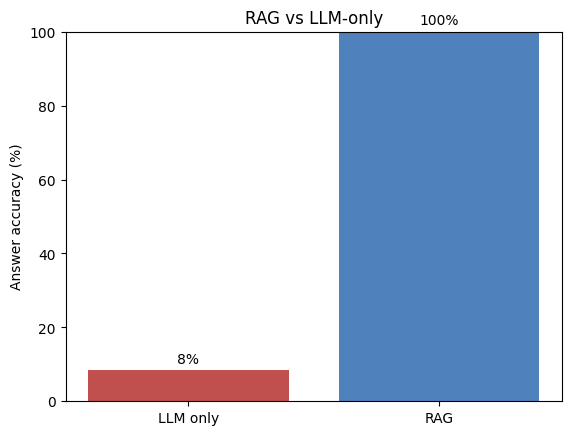

In [19]:
import matplotlib.pyplot as plt
vals = [df.llm_only_correct.mean()*100, df.rag_correct.mean()*100]
plt.bar(['LLM only','RAG'], vals, color=['#c0504d','#4f81bd'])
plt.ylabel('Answer accuracy (%)'); plt.ylim(0,100); plt.title('RAG vs LLM-only')
for i,v in enumerate(vals): plt.text(i, v+2, f'{v:.0f}%', ha='center')
plt.show()